In [1]:
using Revise
using StableRNGs
import LazySets
using LinearAlgebra
using NLsolve
using Plots
using Printf
using LaTeXStrings

RNG = StableRNG(93685)
gr();
# pyplot();
# plotlyjs();

In [2]:
BLAS.set_num_threads(1)

In [3]:
using GaussianSpectralDensities

# Dynamics of a random neural network with one planted memory

$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
$$

$$
\begin{aligned}
\frac{d x_i}{dt} &= -x_i + \sum_{j = 1}^N C_{ij} \tanh x_j \ , \\
C &= \hat{C} + \sigma J \, , \quad \hat{C} = \frac{\hat{\bm{x}} \tanh \hat{\bm{x}}^T}{\|\tanh \hat{\bm{x}}\|^2} \, ,\\
\langle J_{ij} J_{kl} \rangle &= \frac{1}{N} \left(\delta_{ik} \delta_{jl} + \tau \delta_{il} \delta_{kj} \right) \, .
\end{aligned}
$$

The memory $\hat{\bm{x}}$ is a randomly sampled vector, and the model
is set up such that, in the absence of coupling noise ($\sigma = 0$),
there is a fixed point at $\bm{x} = \hat{\bm{x}}$. What happens as
noise is turned on, and what is the effect of symmetry $\tau$?

Note that the $\tanh$ breaks rotational symmetry, so different
$\hat{\bm{x}}$ with the same norm do not necessarily give equivalent
dynamics. Should this inform our choice of measure for sampling
memories? No, I think sampling something like a Gaussian $\hat{\bm{x}}$
is the most sensible approach. It maintains permutation invariance
but not full rotational invariance, which actually seems desirable in
a nonlinear model.

Let's study the spectra of some instances of $C$.

In [4]:
# Define ODE function and fixed point solver
function network_f!(dx, x, C, t=zero(eltype(x)))
    mul!(dx, C, tanh.(x))
    dx .-= x
    return nothing
end

function network_jac!(jac, x, C, t=zero(eltype(x)))
    for j in 1:length(x)
        for i in 1:length(x)
            jac[i, j] = C[i, j] / (cosh(x[j])^2)
        end
        jac[j, j] -= one(eltype(jac))
    end
    return nothing
end

function finite_diff_network_jac!(jac, x, C, t=zero(eltype(x)), dx=sqrt(eps(eltype(x))))
    xx = copy(x)
    fx = similar(xx)
    fxdx = similar(xx)
    network_f!(fx, xx, C)
    for j in 1:length(x)
        xx[j] += dx
        network_f!(fxdx, xx, C) 
        jac[:, j] = (fxdx - fx) / (xx[j] - x[j])
        xx[j] = x[j]
    end
    return nothing
end

function fixedpoint(C, x₀)
    sol = nlsolve(
        (dx, xx) -> network_f!(dx, xx, C),
        (jac, xx) -> network_jac!(jac, xx, C),
        x₀;
        method=:newton,
        ftol=sqrt(eps(eltype(x₀))),
    )
    if !converged(sol)
        error("fixed point not found")
    end
    return sol.zero
end;

In [5]:
# Define network parameter samplers
function random_memory(N, s) 
    return s * randn(RNG, typeof(s), N)
end
    
function structured_couplings(x̂)
    tx̂ = tanh.(x̂)
    Ĉ = x̂ * tx̂' / dot(tx̂, tx̂)
    for k in 1:length(x̂)
        Ĉ[k, k] = zero(eltype(Ĉ))
    end
    return Ĉ
end

function random_couplings(N, T)
    J = randpartherm(RNG, eltype(T), N, T)
    for k in 1:N
        J[k, k] = zero(eltype(J))
    end
    return J
end;

In [6]:
# Sample network parameters
x̂ = random_memory(256, 1.0)
σ, τ = eltype(x̂).((0.6, 0.2))
J = random_couplings(length(x̂), τ);

In [7]:
# Perform sanity checks
Ĉ = structured_couplings(x̂)
C = Ĉ + σ * J

## Verify analytic Jacobian
jac, fdjac = similar(C), similar(C)
network_jac!(jac, x̂, C)
finite_diff_network_jac!(fdjac, x̂, C)
@printf("∥jac - fdjac∥ =  %3.2e\n", opnorm(jac - fdjac))

## Find spectral abscissa of Jacobian at fixed point
x̃ = fixedpoint(C, x̂)
network_jac!(jac, x̃, C)
jacevs = eigvals(jac)
@printf("           -Δ = %.4f", maximum(real(jacevs)))

∥jac - fdjac∥ =  5.96e-07
           -Δ = -0.4650

In [8]:
# Define random matrix ensemble for fixed point Jacobian
function planted_memory_ensemble(x̂::AbstractVector, args...)
    return planted_memory_ensemble(structured_couplings(x̂), args..., x̂)
end

function planted_memory_ensemble(Ĉ::AbstractMatrix, σ, T, x₀)
    return planted_memory_ensemble(Ĉ, σ, T, random_couplings(length(x̂), T), x₀)
end

function planted_memory_ensemble(Ĉ::AbstractMatrix, σ, T, J, x₀)
    C = Ĉ + σ * J
    x̃ = fixedpoint(C, x₀)
    L = σ * I
    R = Diagonal(cosh.(x̃).^(-2))
    M = Ĉ * R - I
    return MatrixEnsemble(M, L, R, T), x̃
end;

In [9]:
# Instantiate ensemble, sample instance, and compute eigenvalues
ensemble = planted_memory_ensemble(x̂, σ, τ, J)[1]

Mevs = unique(eigvals(ensemble.M))
A, J2 = randsample(RNG, ensemble)
Aevs = eigvals(A; sortby=nothing);

In [10]:
# Find and discretize region of spectral support
region = spectral_region(Aevs)
xs, ys, zs = automesh(region);

In [11]:
# Select mesh point of interest
i, j = 30, 59
za = zs[i, j + 1]
zb = zs[i - 1, j]
zc = zs[i, j];

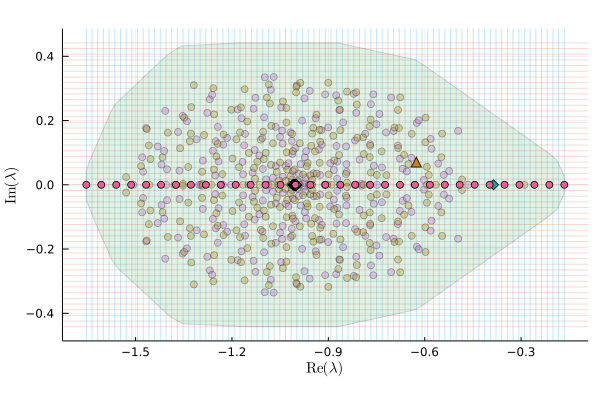

In [12]:
# Plot eigenvalues of actual jacobian and sampled instance, region of spectral support,
# mesh, and point of interest

## Mesh
p = vline(xs, label="", alpha=0.25, xlims=(xs[1], xs[end]))
hline!(p, ys, label="", alpha=0.25, ylims=(ys[1], ys[end]))

## Region
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

## Actual Jacobian eigenvalues
scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")

## Sampled instance eigenvalues
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")

## Eigenvalues of structured part only
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label="")

# 1D mesh for spectral gap solver
xxs = automesh(Aevs, 24^2)[1]
scatter!(p, xxs, zero(xxs); label="")

## Point of interest
scatter!(p, [real(zc)], [imag(zc)], markershape=:utriangle, markersize=5, label="")

In [13]:
objective = Fixk();
algorithm = Rampδ²();

In [14]:
verbosity = 3;

solver = SpectralSolver(ensemble, objective, algorithm);
solutiona = solve!(solver, za; verbosity=verbosity, store_trace=true);
solutionb = solve!(solver, zb; verbosity=verbosity, store_trace=true);
qa, δa² = solutiona.q, solutiona.δ²;
qb, δb² = solutionb.q, solutionb.δ²;
qc0, δc0² = GaussianSpectralDensities.select(qa, qb, δa², δb²);
GaussianSpectralDensities.print_q(qc0);
GaussianSpectralDensities.print_δ²(δc0²);
solutionc = solve!(
    solver, zc,
    qc0, δc0²;
    verbosity=verbosity, store_trace=true,
);

 z = -0.608 + i 0.071
---------------------------------------------------------------------------------------------
    μ       γ²         δ²                  q                k                   r
-------  ----------  ---------  ------------------------  ---------  ------------------------
  1.000   2.556e+02  2.560e+02   2.585e-03 + i-4.672e-04  3.817e-03   1.529e+01 + i-2.762e+00
  1.000   1.276e+02  1.280e+02   4.853e-03 + i-8.786e-04  7.533e-03   2.446e+01 + i-4.420e+00
  1.000   6.360e+01  6.400e+01   8.970e-03 + i-1.629e-03  1.476e-02   3.857e+01 + i-6.982e+00
  1.000   3.160e+01  3.200e+01   1.625e-02 + i-2.969e-03  2.865e-02   5.962e+01 + i-1.083e+01
  1.000   1.560e+01  1.600e+01   2.880e-02 + i-5.319e-03  5.499e-02   8.981e+01 + i-1.643e+01
  1.000   7.601e+00  8.000e+00   4.993e-02 + i-9.413e-03  1.042e-01   1.321e+02 + i-2.450e+01
  1.000   3.608e+00  4.000e+00   8.473e-02 + i-1.658e-02  1.946e-01   1.908e+02 + i-3.638e+01
  1.000   1.635e+00  2.000e+00   1.400e-01 + i-2.9

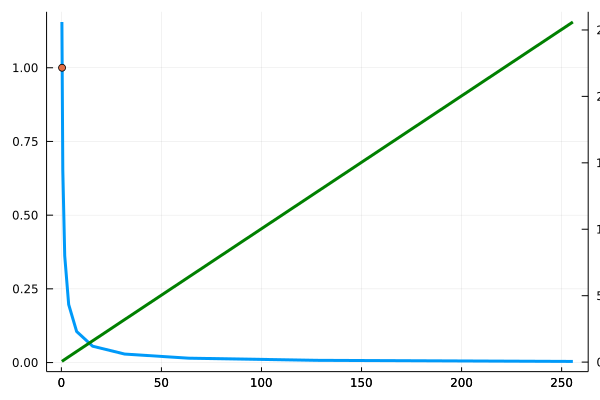

In [15]:
sol = solutionb

p = plot(sol.trace.γ², sol.trace.k, lw=3, label="")
if sol.γ² !== missing
    scatter!(p, [sol.γ²], [sol.k], label="")
end
plot!(twinx(p), sol.trace.γ², sol.trace.δ², lw=3, color=:green, label="")
p

In [16]:
chunks_per_thread = 1
problem = SpectralProblem(ensemble, objective, zs);
solution = solve(problem, algorithm; chunks_per_thread=chunks_per_thread);

In [17]:
ρ, ρxs, ρys = spectral_density(solution, xs, ys);

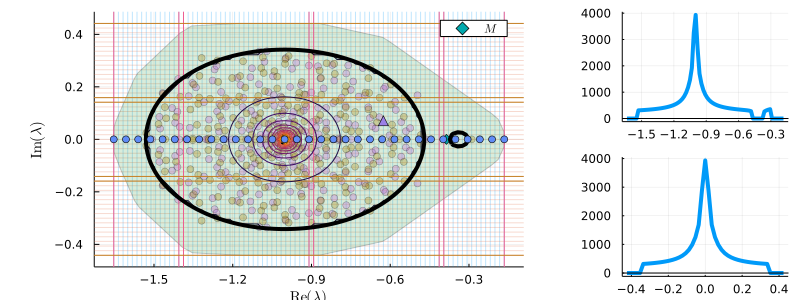

In [18]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(
    p,
    region,
    alpha=0.2,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(jacevs), imag(jacevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Aevs), imag(Aevs), alpha=1.0 / 3.0, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markersize=5, label=L"M")

chunk_rows, chunk_cols = GaussianSpectralDensities.chunk_indices(
    size(zs), chunks_per_thread * Threads.nthreads()
)
chunk_xs, chunk_ys = xs[vcat(chunk_cols...)], ys[vcat(chunk_rows...)]
vline!(p, chunk_xs, label="")
hline!(p, chunk_ys, label="")

contour!(p, ρxs, ρys, ρ, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, linewidth=4)

vline!(p, [0.0], color=:black, label="")

ii, jj = 30, 59
scatter!(p, xs[[jj]], ys[[ii]], markershape=:utriangle, markersize=5, label="")

function plot_section(x, y, level)
    p = plot(x, y, linewidth=4, label="")
    return hline!(p, [level], color=:black, label="")
end

function plot_sections(xs, ys, f; x0=0.0, y0=0.0, level=0.0)
    i, j = argmin(abs2.(ρys .- y0)), argmin(abs2.(ρxs .- x0))
    return [plot_section(x, y, level) for (x, y) in ((xs, f[i, :]), (ys, f[:, j]))]
end

xxs = automesh(Aevs, 24^2)[1]
scatter!(p, xxs, zero(xxs); label="")

l = @layout [a{0.75w} [b; c]]
plot(p, plot_sections(ρxs, ρys, ρ, x0=-1)..., layout=l, size=(800, 300))

So we can get the spectral boundary and spectral density of the linearized dynamics around the planted memory fixed point. Good.

Our goal is to use this to plot a phase diagram in terms of the noise strength $\sigma$ and the noise symmetry $\tau$. To that end, we need to extract the spectral gap, that is, minus the largest real part of the spectral boundary (i.e., minus the spetral abscissa). The spectra obtained from this equation of motion are symmetric around the real axis because the jacobian is real (more generally because $A$, $L$ and $R$ are real, I think? $A$ real means that the "locuses" are symmetrically distributed around the real axis, and the spectrum of $LJR$ with iid. $J$ will have major and minor axes along the real and imaginary axes if $L$ and $R$ are real; this is a little more subtle, but true, you need the RHS of eq. 5b in the draft to always be real), and consists of convex blobs centered on the real axis (because the eigenvalues of $A$ are all real). Thus, the spectral boundary will reach its largest real value where it interesects the real axis, so to solve for it we can confine our attention to the axis and simply walk down from the origin until $\gamma^2$ turns positive. This gives us a bracket (the last step) in which we can use a bisecting root finder to solve for $\gamma^2 = 0$.

In [19]:
import Roots
using Random
# Function evaluations
#     sqrt(n):               24   32   40   48
# --------------------------------------------
# Roots.Bisection:           50   51   51   50
# Roots.FalsePosition{1}:    13   17   13   13  # Winner
# Roots.FalsePosition{2}:    27   20   20   21
# Roots.FalsePosition{3}:    23   22   18   19
# Roots.FalsePosition{4}:    17   15   21   20
# Roots.FalsePosition{5}:    20   20   19   20
# Roots.FalsePosition{6}:    20   21   26   20
# Roots.FalsePosition{7}:    21   19   18   19
# Roots.FalsePosition{8}:    14   17   19   23
# Roots.FalsePosition{9}:    15   13   20   18
# Roots.FalsePosition{10}:   24   16   18   19
# Roots.FalsePosition{11}:   23   14   15   15
# Roots.FalsePosition{12}:   16   17   15   11

spectral_gap(solver, xs, args...) = _spectral_gap(solver, xs, args...)[1]

function _spectral_gap(solver, xs, method=Roots.FalsePosition(1); verbose=false)
    if verbose
        tid = Threads.threadid()
        t0 = time()
        @printf("(%i) t = %5.2f: start\n", tid, time() - t0)
    end
    xmin = xmax = xs[end]
    sol = solve!(solver, complex(xmax))
    if inside(sol.γ²)
        error("the rightmost grid point is inside the spectral support")
    end
    γ²prev = sol.γ²
    for i in (length(xs) - 1):-1:1
        xmin = xs[i]
        sol = solve!(solver, complex(xmin))
        if inside(sol.γ²)
            if verbose
                @printf("(%i) t = %5.2f: inside x = %4.2f found\n", tid, time() - t0, xmin)
            end
            while !outsideandsolvable(γ²prev)
                xmid = 0.5 * (xmin + xmax)
                sol = solve!(solver, complex(xmid))
                if inside(sol.γ²)
                    xmin = xmid
                else
                    xmax = xmid
                    γ²prev = sol.γ²
                end
            end
            break
        end
        xmax = xmin
        γ²prev = sol.γ²
    end
    if verbose
        @printf(
            "(%i) t = %5.2f: bracket = [%4.2f, %4.2f] found\n",
            tid,
            time() - t0,
            xmin,
            xmax,
        )
    end
    
    zproblem = Roots.ZeroProblem(
        method, x -> solve!(solver, complex(x), sol.q, sol.δ²).γ², (xmin, xmax)
    )
    Δ = -Roots.find_zero!(zproblem)
    if verbose; @printf("(%i) t = %5.2f: solved\n", tid, time() - t0);  end
    return Δ, zproblem
end

inside(γ²) = ((γ² !== missing) && (γ² >= 0))
outsideandsolvable(γ²) = ((γ² !== missing) && (γ² < 0));

# Cases:
#   γ² !== missing && γ² >= 0: inside spectral support
#   γ² !== missing && γ² < 0:  outside spectral support
#   γ² === missing:            solution not found, usually means that k == 0 has no
#                              solution on correct branch, so outside spectral support

In [20]:
ns = (24:8:48).^2
xss = [automesh(Aevs, n)[1] for n in ns]
methods = [Roots.Bisection(), (Roots.FalsePosition(i) for i in 1:12)...]
fnevals = fill(-1, (length(methods), length(xss)))
solvers = vcat([solver], [deepcopy(solver) for _ in 2:Threads.nthreads()])

Threads.@threads for i in 1:length(methods)
    local_solver = solvers[Threads.threadid()]
    for j in 1:length(xss)
        fnevals[i, j] = _spectral_gap(
            local_solver, xss[j], methods[i]; verbose=true
        )[2].state.fnevals
    end
end

(1) t =  0.00: start
(4) t =  0.00: start
(6) t =  0.00: start
(5) t =  0.00: start
(2) t =  0.00: start
(7) t =  0.00: start
(3) t =  0.00: start
(4) t =  7.68: inside x = -0.31 found
(1) t =  8.43: inside x = -0.31 found
(5) t =  8.27: inside x = -0.31 found
(6) t =  8.57: inside x = -0.31 found
(2) t =  8.98: inside x = -0.31 found
(7) t =  8.75: inside x = -0.31 found
(1) t =  9.99: bracket = [-0.31, -0.28] found
(4) t = 10.30: bracket = [-0.31, -0.28] found
(3) t =  8.97: inside x = -0.31 found
(5) t = 10.56: bracket = [-0.31, -0.28] found
(6) t = 10.93: bracket = [-0.31, -0.28] found
(2) t = 11.32: bracket = [-0.31, -0.28] found
(7) t = 11.13: bracket = [-0.31, -0.28] found
(3) t = 11.36: bracket = [-0.31, -0.28] found
(5) t = 14.17: solved
(5) t =  0.00: start
(4) t = 15.10: solved
(4) t =  0.00: start
(7) t = 16.22: solved
(7) t =  0.00: start
(3) t = 16.07: solved
(3) t =  0.00: start
(6) t = 18.40: solved
(6) t =  0.00: start
(2) t = 18.43: solved
(2) t =  0.00: start
(1) t =

In [21]:
using Printf

label_width = 26
println("# Function evaluations")
print(rpad("#     sqrt(n):", label_width))
for n in ns
    @printf("   %2i", sqrt(n))
end
println()
println("# " * ("-" ^ (label_width - 2 + 5 * length(ns))))
for i in 1:size(fnevals, 1)
    print(rpad("# $(typeof(methods[i])):", label_width))
    for j in 1:size(fnevals, 2)
        @printf("   %2i", fnevals[i, j])
    end
    println()
end

# Function evaluations
#     sqrt(n):               24   32   40   48
# --------------------------------------------
# Roots.Bisection:           50   51   51   50
# Roots.FalsePosition{1}:    13   17   13   13
# Roots.FalsePosition{2}:    27   20   20   21
# Roots.FalsePosition{3}:    23   22   18   19
# Roots.FalsePosition{4}:    17   15   21   20
# Roots.FalsePosition{5}:    20   20   19   20
# Roots.FalsePosition{6}:    20   21   26   20
# Roots.FalsePosition{7}:    21   19   18   19
# Roots.FalsePosition{8}:    14   17   19   23
# Roots.FalsePosition{9}:    15   13   20   18
# Roots.FalsePosition{10}:   24   16   18   19
# Roots.FalsePosition{11}:   23   14   15   15
# Roots.FalsePosition{12}:   16   17   15   11


In [22]:
function fixed_points_and_spectral_gaps!(
    x̃s, Δs, x̂, iid, iid2, σs, Ts, algorithm=Rampδ²(), n=16^2; verbose=false
)
    objective = Fixk()
    Ĉ = structured_couplings(x̂)

    if verbose; println("Thread  σ     T"); println("-----------------"); end
    Threads.@threads for i in 1:length(Ts)
        T = Ts[i]
        J = partially_hermitize(iid, T)
        J2 = partially_hermitize(iid2, T)
        x̃ = x̂
        ensemble = planted_memory_ensemble(Ĉ, one(eltype(σs)), T, J, x̃)[1]
        solver = SpectralSolver(ensemble, objective, algorithm)
        A = transform(ensemble, J2; hermitize=false)[1]
        for (j, σ) in enumerate(σs)
            if verbose; @printf("   %2i  %.2f  %.2f\n", Threads.threadid(), σ, T); end
            try
                ensemble, x̃ = planted_memory_ensemble(Ĉ, σ, τ, J, x̃)
            catch
                break
            end
            update_ensemble!(solver, ensemble)
            x̃s[:, j, i] = x̃
            transform!(A, ensemble, J2; hermitize=false)
            xs = automesh!(A, n; margin=0.15)[1]
            Δs[j, i] = spectral_gap(solver, xs)
        end
    end
    return nothing
end;

In [23]:
# Sample randomness
N = length(x̂)
ftype = eltype(x̂)
iid, iid2 = randiid(RNG, ftype, N), randiid(RNG, ftype, N)
iid[diagind(iid)] .= zero(ftype);

In [24]:
# Define parameter grid
σs = ftype(0.05):ftype(0.05):ftype(1.5)
τs = ftype(0.0):ftype(1.0 / 6.0):ftype(1.0);

In [25]:
# Allocate output arrays
x̃s = fill(ftype(NaN), (N, length(σs), length(τs)))
Δs = fill(ftype(NaN), (length(σs), length(τs)));

In [26]:
# Go!
fixed_points_and_spectral_gaps!(x̃s, Δs, x̂, iid, iid2, σs, τs);

LoadError: TaskFailedException

[91m    nested task error: [39mthe rightmost grid point is inside the spectral support
    Stacktrace:
     [1] [0m[1merror[22m[0m[1m([22m[90ms[39m::[0mString[0m[1m)[22m
    [90m   @ [39m[90mBase[39m [90m./[39m[90;4merror.jl:33[0m
     [2] [0m[1m_spectral_gap[22m[0m[1m([22m[90msolver[39m::[0mSpectralSolver[90m{Float64, GaussianSpectralDensities.Workspace{Float64, Matrix{Float64}, UniformScaling{Float64}, Diagonal{Float64, Vector{Float64}}, Diagonal{ComplexF64, Vector{ComplexF64}}, Matrix{ComplexF64}}, Fixk{false, Float64}, Rampδ²{Float64}}[39m, [90mxs[39m::[0mLinRange[90m{Float64}[39m, [90mmethod[39m::[0mRoots.FalsePosition[90m{1}[39m; [90mverbose[39m::[0mBool[0m[1m)[22m
    [90m   @ [39m[35mMain[39m [90m./[39m[90;4mIn[19]:32[0m
     [3] [0m[1m_spectral_gap[22m[90m (repeats 2 times)[39m
    [90m   @ [39m[90m./[39m[90;4mIn[19]:24[0m[90m [inlined][39m
     [4] [0m[1mspectral_gap[22m[

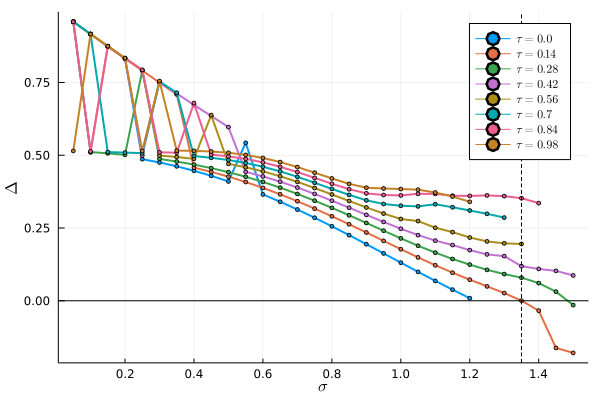

In [107]:
plot(
    σs,
    Δs,
    linewidth=2,
    marker=:o,
    markersize=2,
    label=permutedims([L"\tau = %$τ" for τ in τs]),
)
xlabel!(L"\sigma")
ylabel!(L"\Delta")
hline!([0], color=:black, label="")
vl = [1.35]
vline!(vl, color=:black, linestyle=:dash, label="")

We're onto something here. What do we actually want to accomplish?

This shows the spectral gap for different levels of noise. The fixed point goes unstable when this shrinks to zero. What I'd like to do is to find this point for different values of $\tau$, the symmetry parameter, so that I can draw a phase diagram. Ideally I'll sample a few different noise instantiations for each pair of values.

I don't care about locating the phase boundary very exactly---it's blurred by noise at accessible matrix sizes anyway. Hence, no further root finding is relevant, I should just sample the spectral gap and use contour plotting to distinguish the phases.

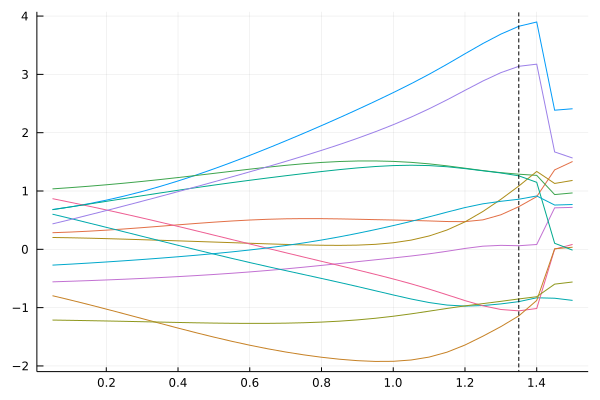

In [109]:
plot(σs, x̃s[1:12, :, 2]', label="")
vline!(vl, color=:black, linestyle=:dash, label="")

In [158]:
display([σs Δs])

5×2 Matrix{Float64}:
 0.6    0.32022
 0.8    0.200802
 1.0    0.0408344
 1.2   -0.0972153
 1.4  NaN

In [ ]:
M = similar(ensemble.M)
R = similar(ensemble.R)
σs = ftype(0.5):ftype(0.5):ftype(1.5)
x₀s = fill(ftype(NaN), (length(x̂), length(σs)))
x₀ = x̂
p = plot()
for (i, σ) in enumerate(σs)
    C = Ĉ + σ * J
    try
        x₀s[:, i] = x₀ = fixedpoint(C, x₀)
    catch
        break
    end
    R .= Diagonal(cosh.(x₀).^(-2))
    mul!(M, Ĉ, R)
    M[diagind(M)] .-= 1
    ensemble = MatrixEnsemble(M, σ * I, R, τ)
    AA = Jalt * ensemble.R
    lmul!(ensemble.L, AA)
    AA .+= ensemble.M
    xs, ys, zs = autogrid(spectral_region!(AA))
    problem = SpectralProblem(ensemble, Fixk(), zs)
    solution = solve(problem, algorithm)
    contour!(
        p, xs, ys, solution.γ²; levels=[0.0], color=:black, linewidth=4, colorbar=false
    )
end
p

In [44]:
[σs x₀s[1, :]]

3×2 Matrix{Float64}:
 0.5    0.618604
 1.0    0.34127
 1.5  NaN

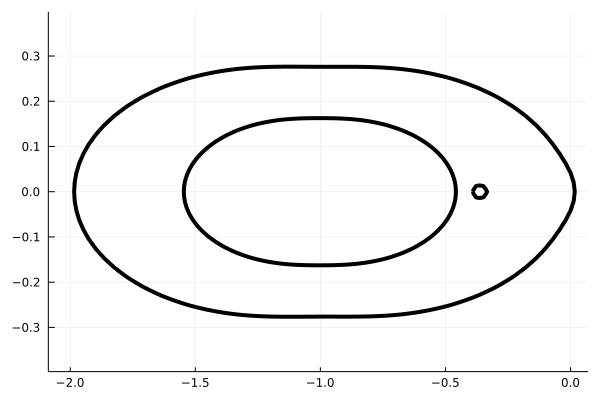

In [45]:
p